# 23. 실험 1 — KAMP 라벨 섞기 검정
질문: raw PVC가 KAMP의 날짜별 불량 개수(라벨)에서 무언가 배웠는가, 아니면 라벨과 무관하게 데이터 모양만 고르는가.

**설계(실행 전 고정)**
- 사양은 br/spec.py 그대로(raw PVC: 입력 7개, PVC 개수 손실 MLP, 10시드 평균). 바꾸지 않는다.
- 주 분석 = **8일 전체로 1회 학습** 후 9일 전체 타점에 점수(시드당 약 2초). 원래 추천 목록의 날짜 하나 빼기(LODO) 방식으로 30회 × 10시드를 돌리면 약 82분이라,
  LODO는 **확인용으로 10회만** 돌린다(반복 횟수 축소, 보고서에 명시).
- 실제 라벨: 시드 0~9(A), 10~19(B). 기준선 = A와 B의 날짜별 상위 10% 겹침(같은 라벨, 다른 시드).
- 섞은 라벨: 8일의 불량 개수를 날짜끼리 무작위 순열(합계 39 유지, 실제와 같은 배열은 제외) 30회, 순열 난수 시드 2026. 각 10시드(0~9).
- 고정 불량률 라벨: 날짜마다 round(39 × 그날 타점 수 / 8일 타점 수).
- 결합 모델: 각 raw PVC 점수와 D4(학습 없음)의 날짜 안 순위 평균. D4는 라벨과 무관하다.
- 복사 블록 행은 순위에서 뺀다(기존과 같음). 9일(3/27 포함) 모두 순위를 매긴다.

**판정 기준(고정)**: 섞은 라벨 모델과 실제 라벨 모델 A의 겹침 30개 값을 기준선(A vs B 겹침, 날짜 복원추출 95% 구간)과 비교한다.
- 30개 겹침의 중앙값이 기준선 구간 하한 이상 → "라벨에서 배운 것이 없다(라벨을 바꿔도 같은 타점을 고른다)".
- 30개 겹침의 97.5 백분위가 기준선 구간 하한보다 낮음 → "라벨 정보를 쓴다".
- 그 사이 → "라벨의 영향이 일부 있으나 작다".

In [1]:
import time, pickle, warnings, numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import spearmanr
import br
from br import spec as S, validity as V, plot as P
from wl import kamp as wlkamp
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
Xk, kday, kcnt, _, kblk = S.load_kamp()
lab_days = list(kcnt.dropna().index); lab = np.isin(kday, lab_days)
u, bag = np.unique(kday[lab], return_inverse=True)
real = kcnt.loc[u].values.astype(int)
n_day = pd.Series(kday[lab]).value_counts().loc[u].values
const = np.round(real.sum() * n_day / n_day.sum()).astype(int)
rng = np.random.default_rng(2026); perms = []
while len(perms) < 30:
    p_ = rng.permutation(real)
    if not np.array_equal(p_, real): perms.append(p_)
LABELS = {"real": real, "const": const, **{f"perm{i+1:02d}": p_ for i, p_ in enumerate(perms)}}
pd.DataFrame(LABELS, index=u).T.to_csv(br.RES / "exp1_label_sets.csv", encoding="utf-8-sig")
print("실제:", real.tolist(), "| 고정 불량률:", const.tolist(), "합", const.sum())
PLAN = [("real", s) for s in range(20)] + [("const", s) for s in range(10)] + [(f"perm{i:02d}", s) for i in range(1, 31) for s in range(10)]

cache = br.RES / "exp1_fullfit_scores.pkl"
sc = pickle.load(open(cache, "rb")) if cache.exists() else {}
t0 = time.time()
for key in PLAN:
    if key in sc or time.time() - t0 > 510: continue
    sc[key] = S.fit_score("PVC MLP", Xk, bag, LABELS[key[0]], lab, np.ones(len(kday), bool), key[1])[0]
    pickle.dump(sc, open(cache, "wb"))
print(f"주 분석 학습: {sum(k in sc for k in PLAN)}/{len(PLAN)}  ({time.time()-t0:.0f}초)")

# LODO 확인용: 실제 라벨 시드 10~19, 섞은 라벨 perm01~perm10 × 시드 0~9 (실제 라벨 시드 0~9는 기존 캐시 사용)
def lodo_counts(labels):
    return pd.Series(labels, index=u).reindex(kcnt.index)
PLAN_L = [("real", s) for s in range(10, 20)] + [(f"perm{i:02d}", s) for i in range(1, 11) for s in range(10)]
cache_l = br.RES / "exp1_lodo_scores.pkl"
scl = pickle.load(open(cache_l, "rb")) if cache_l.exists() else {}
if all(k in sc for k in PLAN):
    for key in PLAN_L:
        if key in scl or time.time() - t0 > 510: continue
        scl[key] = S.lodo("PVC MLP", Xk, kday, lodo_counts(LABELS[key[0]]), key[1])[0]
        pickle.dump(scl, open(cache_l, "wb"))
print(f"LODO 확인 학습: {sum(k in scl for k in PLAN_L)}/{len(PLAN_L)}  (누적 {time.time()-t0:.0f}초)")
DONE_MAIN = all(k in sc for k in PLAN); DONE_LODO = all(k in scl for k in PLAN_L)

실제: [4, 8, 7, 4, 5, 4, 4, 3] | 고정 불량률: [5, 5, 4, 6, 7, 8, 3, 3] 합 41
주 분석 학습: 330/330  (0초)
LODO 확인 학습: 110/110  (누적 0초)


## 결과 (학습이 끝난 뒤 계산)

In [2]:
K, _ = wlkamp.load_kamp(); cur = K.cur_mean.values
ok = ~kblk
D4 = S.load_kamp("derived5_absz")[0].sum(axis=1).values
R_D4 = V.day_rank(D4, kday, ok)
comb = lambda s: (V.day_rank(s, kday, ok) + R_D4) / 2
def mean_of(store, name, seeds): return np.mean([store[(name, s)] for s in seeds], 0)

def analyse(store, A, B, perm_names, const_s=None, tag=""):
    rows = []
    base = V.overlap_days(A, B, kday, ok); bm, bl, bh = V.boot_ci(base)
    base_c = V.overlap_days(comb(A), comb(B), kday, ok); cm, cl, ch = V.boot_ci(base_c)
    lowA = V.low_current_frac(A, cur, kday, ok); lowAc = V.low_current_frac(comb(A), cur, kday, ok)
    po, poc, low_p, low_pc, rho = [], [], [], [], []
    for nm in perm_names:
        s_ = mean_of(store, nm, range(10))
        po.append(V.overlap_days(s_, A, kday, ok).mean()); poc.append(V.overlap_days(comb(s_), comb(A), kday, ok).mean())
        low_p.append(V.low_current_frac(s_, cur, kday, ok)); low_pc.append(V.low_current_frac(comb(s_), cur, kday, ok))
        rho.append(spearmanr(LABELS[nm], real).statistic)
    po, poc, low_p, low_pc = map(np.array, (po, poc, low_p, low_pc))
    q = lambda x: f"{np.median(x):.3f} [{np.quantile(x, .025):.3f}, {np.quantile(x, .975):.3f}]"
    out = {"기준선: 실제 라벨 A vs B (평균 [날짜 복원추출 95%])": (f"{bm:.3f} [{bl:.3f}, {bh:.3f}]", f"{cm:.3f} [{cl:.3f}, {ch:.3f}]"),
           f"섞은 라벨 vs 실제 라벨 A ({len(perm_names)}회: 중앙값 [2.5, 97.5 백분위])": (q(po), q(poc))}
    if const_s is not None:
        out["고정 불량률 라벨 vs 실제 라벨 A"] = (f"{V.overlap_days(const_s, A, kday, ok).mean():.3f}", f"{V.overlap_days(comb(const_s), comb(A), kday, ok).mean():.3f}")
    tab = pd.DataFrame(out, index=["raw PVC 상위 10% 겹침", "결합 상위 10% 겹침"]).T
    def verdict(x, lo):
        if np.median(x) >= lo: return "라벨에서 배운 것이 없다"
        if np.quantile(x, .975) < lo: return "라벨 정보를 쓴다"
        return "라벨 영향이 일부 있으나 작다"
    low = pd.DataFrame({
        "그날 중앙값 기준": [f"{lowA[0]:.3f}", q(low_p[:, 0])] + ([f"{V.low_current_frac(const_s, cur, kday, ok)[0]:.3f}"] if const_s is not None else []),
        "전체 중앙값 기준(기존 83.1% 정의)": [f"{lowA[1]:.3f}", q(low_p[:, 1])] + ([f"{V.low_current_frac(const_s, cur, kday, ok)[1]:.3f}"] if const_s is not None else []),
        "결합·그날 기준": [f"{lowAc[0]:.3f}", q(low_pc[:, 0])] + ([f"{V.low_current_frac(comb(const_s), cur, kday, ok)[0]:.3f}"] if const_s is not None else []),
        "결합·전체 기준": [f"{lowAc[1]:.3f}", q(low_pc[:, 1])] + ([f"{V.low_current_frac(comb(const_s), cur, kday, ok)[1]:.3f}"] if const_s is not None else []),
    }, index=["실제 라벨 A", "섞은 라벨"] + (["고정 불량률 라벨"] if const_s is not None else []))
    return tab, low, verdict(po, bl), verdict(poc, cl), dict(po=po, poc=poc, rho=np.array(rho), base=(bm, bl, bh), base_c=(cm, cl, ch), low_p=low_p, lowA=lowA)

if DONE_MAIN:
    A, B = mean_of(sc, "real", range(10)), mean_of(sc, "real", range(10, 20))
    tab, low, v1, v2, R1 = analyse(sc, A, B, [f"perm{i:02d}" for i in range(1, 31)], mean_of(sc, "const", range(10)))
    print("[주 분석: 8일 전체 학습]"); display(tab); print("추천 상위 10% 중 '전류 < 기준 − 0.1 kA' 비율"); display(low)
    print("판정 — raw PVC:", v1, "| 결합:", v2)
    print("섞은 라벨과 실제 라벨의 순위상관 vs 겹침 상관:", round(spearmanr(R1["rho"], R1["po"]).statistic, 3))
    tab.to_csv(br.RES / "exp1_main_overlap.csv", encoding="utf-8-sig"); low.to_csv(br.RES / "exp1_main_lowcurrent.csv", encoding="utf-8-sig")

[주 분석: 8일 전체 학습]


,raw PVC 상위 10% 겹침,결합 상위 10% 겹침
기준선: 실제 라벨 A vs B (평균 [날짜 복원추출 95%]),"0.877 [0.818, 0.928]","0.967 [0.958, 0.975]"
"섞은 라벨 vs 실제 라벨 A (30회: 중앙값 [2.5, 97.5 백분위])","0.307 [0.032, 0.724]","0.554 [0.208, 0.856]"
고정 불량률 라벨 vs 실제 라벨 A,0.186,0.411


추천 상위 10% 중 '전류 < 기준 − 0.1 kA' 비율


,그날 중앙값 기준,전체 중앙값 기준(기존 83.1% 정의),결합·그날 기준,결합·전체 기준
실제 라벨 A,0.842,0.998,0.725,0.879
섞은 라벨,"0.480 [0.058, 0.834]","0.616 [0.054, 0.987]","0.471 [0.182, 0.703]","0.585 [0.224, 0.849]"
고정 불량률 라벨,0.196,0.284,0.314,0.399


판정 — raw PVC: 라벨 정보를 쓴다 | 결합: 라벨 정보를 쓴다
섞은 라벨과 실제 라벨의 순위상관 vs 겹침 상관: 0.421


In [3]:
if DONE_MAIN and DONE_LODO:
    old = pd.read_pickle(br.RES / "same_model_scores.pkl")
    old = old[(old.data == "kamp") & (old.model == "PVC MLP")]
    store = {("real", s): g.sort_values("row").score.values for s, g in old.groupby("seed")}; store.update(scl)
    A_l, B_l = mean_of(store, "real", range(10)), mean_of(store, "real", range(10, 20))
    okl = ok & ~np.isnan(A_l)                            # LODO는 정답 없는 3/27에 점수가 없다
    ok_bak = ok; ok = okl
    tabL, lowL, v1L, v2L, R2 = analyse(store, A_l, B_l, [f"perm{i:02d}" for i in range(1, 11)])
    ok = ok_bak
    print("[확인: 날짜 하나 빼기(LODO), 섞은 라벨 10회]"); display(tabL); display(lowL); print("판정 — raw PVC:", v1L, "| 결합:", v2L)
    tabL.to_csv(br.RES / "exp1_lodo_overlap.csv", encoding="utf-8-sig"); lowL.to_csv(br.RES / "exp1_lodo_lowcurrent.csv", encoding="utf-8-sig")

[확인: 날짜 하나 빼기(LODO), 섞은 라벨 10회]


,raw PVC 상위 10% 겹침,결합 상위 10% 겹침
기준선: 실제 라벨 A vs B (평균 [날짜 복원추출 95%]),"0.825 [0.731, 0.900]","0.894 [0.861, 0.927]"
"섞은 라벨 vs 실제 라벨 A (10회: 중앙값 [2.5, 97.5 백분위])","0.295 [0.123, 0.537]","0.562 [0.443, 0.747]"


,그날 중앙값 기준,전체 중앙값 기준(기존 83.1% 정의),결합·그날 기준,결합·전체 기준
실제 라벨 A,0.790,0.963,0.691,0.848
섞은 라벨,"0.493 [0.217, 0.750]","0.641 [0.240, 0.914]","0.457 [0.323, 0.677]","0.613 [0.400, 0.827]"


판정 — raw PVC: 라벨 정보를 쓴다 | 결합: 라벨 정보를 쓴다


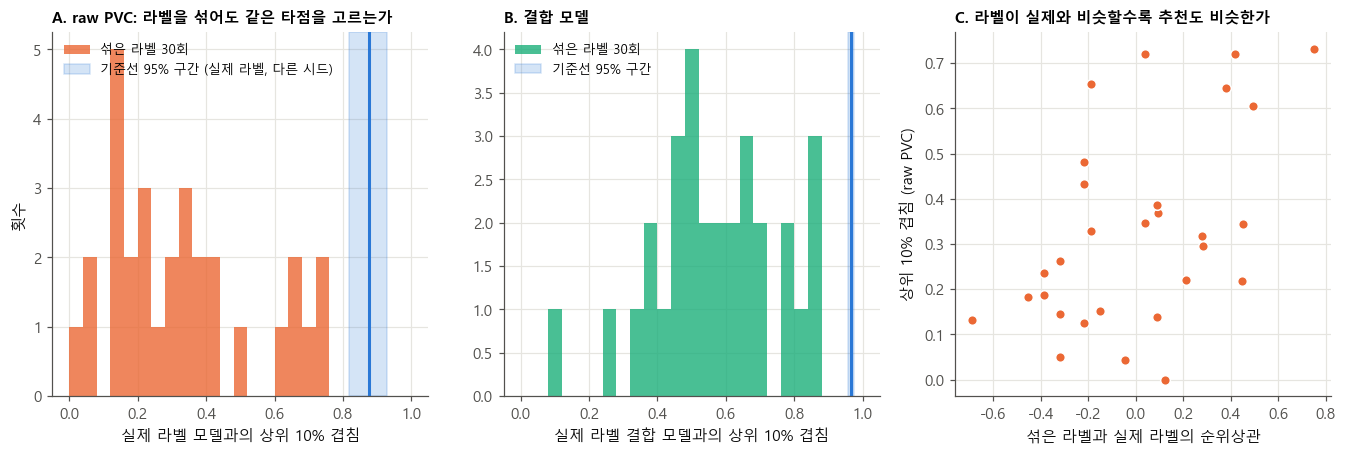

In [4]:
if DONE_MAIN:
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))
    ax = axes[0]
    ax.hist(R1["po"], bins=np.linspace(0, 1, 26), color=P.PAL[1], alpha=.8, label="섞은 라벨 30회")
    ax.axvspan(R1["base"][1], R1["base"][2], color=P.PAL[0], alpha=.2, label="기준선 95% 구간 (실제 라벨, 다른 시드)")
    ax.axvline(R1["base"][0], color=P.PAL[0], lw=2)
    ax.set_xlabel("실제 라벨 모델과의 상위 10% 겹침"); ax.set_ylabel("횟수"); ax.legend(fontsize=8.5)
    ax.set_title("A. raw PVC: 라벨을 섞어도 같은 타점을 고르는가", loc="left", fontweight="bold", fontsize=10)
    ax = axes[1]
    ax.hist(R1["poc"], bins=np.linspace(0, 1, 26), color=P.PAL[2], alpha=.8, label="섞은 라벨 30회")
    ax.axvspan(R1["base_c"][1], R1["base_c"][2], color=P.PAL[0], alpha=.2, label="기준선 95% 구간")
    ax.axvline(R1["base_c"][0], color=P.PAL[0], lw=2)
    ax.set_xlabel("실제 라벨 결합 모델과의 상위 10% 겹침"); ax.legend(fontsize=8.5)
    ax.set_title("B. 결합 모델", loc="left", fontweight="bold", fontsize=10)
    ax = axes[2]
    ax.scatter(R1["rho"], R1["po"], s=40, color=P.PAL[1], edgecolor="white")
    ax.set_xlabel("섞은 라벨과 실제 라벨의 순위상관"); ax.set_ylabel("상위 10% 겹침 (raw PVC)")
    ax.set_title("C. 라벨이 실제와 비슷할수록 추천도 비슷한가", loc="left", fontweight="bold", fontsize=10)
    P.save(fig, "20_exp1_label_shuffle"); plt.show()

## 보완: 단일 값의 95% 구간 (날짜 복원추출)

In [5]:
def low_by_day(score, okm):
    T = V.top_sets(score, kday, okm); med = pd.Series(cur[okm]).groupby(kday[okm]).median(); g_med = np.median(cur[okm])
    return np.array([[sum(cur[i] < med[d] - .1 for i in T[d]), sum(cur[i] < g_med - .1 for i in T[d]), len(T[d])] for d in sorted(T)], float)
def ratio_ci(arr, col, nb=5000, seed=3):
    rng = np.random.default_rng(seed); v = []
    for _ in range(nb):
        ii = rng.integers(0, len(arr), len(arr)); v.append(arr[ii, col].sum() / arr[ii, 2].sum())
    return f"{arr[:, col].sum() / arr[:, 2].sum():.3f} [{np.quantile(v,.025):.3f}, {np.quantile(v,.975):.3f}]"
if DONE_MAIN:
    Cst = mean_of(sc, "const", range(10))
    rows = []
    for nm, s_ in [("실제 라벨 A (raw PVC)", A), ("고정 불량률 라벨 (raw PVC)", Cst), ("실제 라벨 A (결합)", comb(A)), ("고정 불량률 라벨 (결합)", comb(Cst))]:
        arr = low_by_day(s_, ok)
        rows.append({"모델": nm, "저전류 비율 (그날 중앙값 기준)": ratio_ci(arr, 0), "저전류 비율 (전체 중앙값 기준)": ratio_ci(arr, 1)})
    ovc = V.boot_ci(V.overlap_days(Cst, A, kday, ok)); ovcc = V.boot_ci(V.overlap_days(comb(Cst), comb(A), kday, ok))
    rows.append({"모델": "고정 불량률 vs 실제 A 겹침", "저전류 비율 (그날 중앙값 기준)": f"raw PVC {ovc[0]:.3f} [{ovc[1]:.3f}, {ovc[2]:.3f}]",
                 "저전류 비율 (전체 중앙값 기준)": f"결합 {ovcc[0]:.3f} [{ovcc[1]:.3f}, {ovcc[2]:.3f}]"})
    sup = pd.DataFrame(rows); sup.to_csv(br.RES / "exp1_supplement_ci.csv", index=False, encoding="utf-8-sig"); display(sup)

,모델,저전류 비율 (그날 중앙값 기준),저전류 비율 (전체 중앙값 기준)
0,실제 라벨 A (raw PVC),"0.842 [0.582, 1.000]","0.998 [0.994, 1.000]"
1,고정 불량률 라벨 (raw PVC),"0.196 [0.129, 0.252]","0.284 [0.219, 0.373]"
2,실제 라벨 A (결합),"0.725 [0.488, 0.885]","0.879 [0.798, 0.949]"
3,고정 불량률 라벨 (결합),"0.314 [0.217, 0.381]","0.399 [0.357, 0.451]"
4,고정 불량률 vs 실제 A 겹침,"raw PVC 0.186 [0.149, 0.225]","결합 0.411 [0.370, 0.450]"
